# Exploratory Data Analysis: Members
In this notebook, I investigate the Expeditions dataset and assess its suitability for a data warehouse following the Medallion architecture. The raw data serves as the Bronze layer, forming the basis for creating a Silver-layer Star schema of fact and dimension tables.

The main points of emphasis are:
- __data cleanliness:__ data type alignment, missing values, distributions
- __adherence to normal forms:__ key integrity, atomicity, transitive dependencies
- __feature selection:__ deciding which columns are of interest for a subject-oriented data warehouse

The aim is to come up with a feasible data warehouse schema, uncover potential weaknesses in the data, and identify required transformations. A structured and tested ETL pipeline will be built based on the findings in this notebook.

In [177]:
from himalayan_db_pipeline.config import PROJECT_ROOT
from himalayan_db_pipeline.utils import read_dbf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [178]:
FILE_PATH = PROJECT_ROOT / "data" / "members.DBF"

## Overview

In [179]:
df = read_dbf(FILE_PATH)

In [180]:
df.head()

,EXPID,MEMBID,PEAKID,MYEAR,MSEASON,FNAME,LNAME,SEX,AGE,BIRTHDATE,...,MEMBERMEMO,NECROLOGY,MSMTBID,MSMTTERM,HCN,MCHKSUM,MSMTNOTE1,MSMTNOTE2,MSMTNOTE3,DEATHRTE
0,AMAD78301,01,AMAD,1978,3,Jean Robert,Clemenson,M,0,None,...,NaN,NaN,1,4,0,2426937,NaN,NaN,NaN,NaN
1,AMAD78301,02,AMAD,1978,3,Bernard,Dufour,M,0,None,...,NaN,NaN,1,4,0,2426501,NaN,NaN,NaN,NaN
2,AMAD78301,03,AMAD,1978,3,Philippe,Gerard,M,0,None,...,NaN,NaN,1,4,0,2431569,NaN,NaN,NaN,NaN
3,AMAD78301,04,AMAD,1978,3,Eric,Lasserre,M,0,None,...,NaN,NaN,1,4,0,2426809,NaN,NaN,NaN,NaN
4,AMAD78301,05,AMAD,1978,3,Guy,Peters,M,0,None,...,NaN,NaN,1,4,0,2429215,NaN,NaN,NaN,NaN


In [181]:
df.dtypes.value_counts()

bool       27
str        21
int64      19
object      7
float64     4
Name: count, dtype: int64

In [182]:
df.isna().mean().sort_values(ascending=False)[:15]

BIRTHDATE     1.000000
MSMTDATE3     0.999768
MSMTDATE2     0.994895
INJURYDATE    0.988874
DEATHDATE     0.987789
NECROLOGY     0.945642
MEMBERMEMO    0.868578
MSMTNOTE3     0.767787
MSMTNOTE2     0.767208
MSMTNOTE1     0.764208
DEATHRTE      0.758061
MSPEED        0.462531
MSMTDATE1     0.324203
MASCENT3      0.000000
MO2USED       0.000000
dtype: float64

In [183]:
# convert column names to lower case
df.columns = map(lambda x: x.lower(), df.columns)

Notes:
- the data contains a blend of string, numerical, and boolean variables
- provided primary key column to be validated
- many variables with over 50% of missing values

## Data quality assessment
In this section, I investigate the quality of individual variables, proceding by data type (text, numeric, boolean). Different types have different cleanliness indicators.

### Text variables
Text-based columns usually represent discete variables that constitute groupings of data points. With such features, I am particularly interested in __cardinality__ (number of unique values), __missing values__, and __structure__.

Cardinality represents the number of groupings in the data along a particular dimension. I want to detect and inspect columns with particularly high or low cardinality, as they may limited significance in analyses.

With unstructured text, entries do not belong to a finite set of possible values and are unique across the dateset. Unless the values adhere to some patterns, such variables are often meaningless for analytical queries.

In [184]:
# treat empty strings as missing values
df = df.replace(r'^\s*$', np.nan, regex=True)

In [185]:
df.select_dtypes(include=[str]).isna().mean().sort_values(ascending=False)

msmttime3     0.999926
injurytime    0.999084
msmttime2     0.997147
deathtime     0.993916
deathnote     0.978863
necrology     0.945652
membermemo    0.868767
mo2note       0.838304
msmttime1     0.695186
occupation    0.376183
residence     0.115601
yob           0.056990
lname         0.011874
fname         0.001084
citizen       0.000074
status        0.000011
membid        0.000000
sex           0.000000
myear         0.000000
peakid        0.000000
expid         0.000000
dtype: float64

In [186]:
df.yob.str.isnumeric().all()

np.False_

In [187]:
df.loc[~df.yob.str.isnumeric()].yob.unique()

<ArrowStringArray>
[nan]
Length: 1, dtype: str

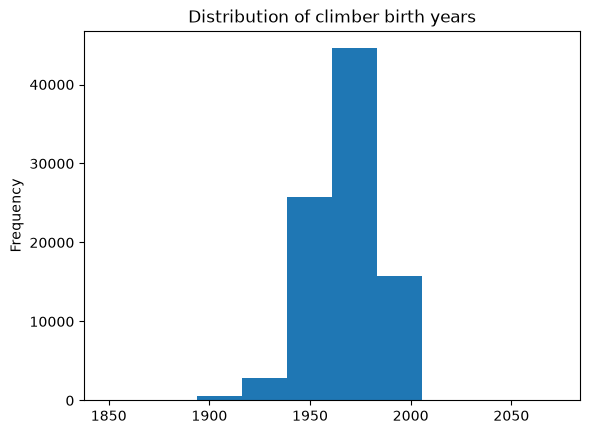

In [188]:
df.yob.astype(pd.Int32Dtype()).plot(kind="hist")
plt.title("Distribution of climber birth years")
plt.show()

In [189]:
df.sex.value_counts()

sex
M    85314
F     9684
X        1
Name: count, dtype: int64

In [190]:
df.membid.str.isnumeric().all()

np.True_

In [191]:
df.loc[df.myear.notna()].myear.str.isnumeric().all()

np.True_

In [192]:
df.msmttime1.value_counts(ascending=False)[:10]

msmttime1
1100    1081
1000    1027
0900     964
0800     913
0930     900
1200     899
1030     848
0830     798
0700     750
0630     742
Name: count, dtype: int64

In [193]:
print(df.msmttime1.isna().sum())
df["summit_1_time"] = pd.to_datetime(df.msmttime1, format="%H%M", errors="coerce")
df["summit_1_hr"] = df.summit_1_time.dt.hour
df["summit_1_min"] = df.summit_1_time.dt.minute
print(df.summit_1_time.isna().sum())

66042
66042


In [194]:
print(df.msmttime2.isna().sum())
df["summit_2_time"] = pd.to_datetime(df.msmttime2, format="%H%M", errors="coerce")
df["summit_2_hr"] = df.summit_2_time.dt.hour
df["summit_2_min"] = df.summit_2_time.dt.minute
print(df.summit_2_time.isna().sum())

94728
94728


In [195]:
print(df.msmttime3.isna().sum())
df["summit_3_time"] = pd.to_datetime(df.msmttime3, format="%H%M", errors="coerce")
df["summit_3_hr"] = df.summit_3_time.dt.hour
df["summit_3_min"] = df.summit_3_time.dt.minute
print(df.summit_3_time.isna().sum())

94992
94992


In [196]:
print(df.injurytime.isna().sum())
df["injury_time"] = pd.to_datetime(df.injurytime, format="%H%M", errors="coerce")
df["injury_hr"] = df.injury_time.dt.hour
df["injury_min"] = df.injury_time.dt.minute
print(df.injury_time.isna().sum())

94912
94912


In [197]:
print(df.deathtime.isna().sum())
df["death_time"] = pd.to_datetime(df.deathtime, format="%H%M", errors="coerce")
df["death_hr"] = df.death_time.dt.hour
df["death_min"] = df.death_time.dt.minute
print(df.death_time.isna().sum())

94421
94421


In [198]:
df.occupation.nunique()

15061

In [199]:
df.occupation.value_counts(ascending=False)[:10]

occupation
Alpine guide           6456
Physician              2399
Engineer               1645
Student                1086
Alpinist                924
Teacher                 691
Attorney                635
Photographer            438
Alpine instructor       409
Mechanical engineer     391
Name: count, dtype: int64

In [200]:
df.status.nunique()

572

In [201]:
df.status.value_counts(ascending=False)[:15]

status
Climber            55053
H-A Worker         20477
Leader             11465
Exp Doctor          1459
Deputy Leader       1244
Sirdar               605
H-A Assistant        391
BC Manager           389
Climbing Leader      380
Co-Leader            371
Member               339
Rope-Fixing          295
Climbing Guide       235
Cameraman            150
Film Team            143
Name: count, dtype: int64

In [202]:
df.select_dtypes(include=[str]).columns

Index(['expid', 'membid', 'peakid', 'myear', 'fname', 'lname', 'sex', 'yob',
       'citizen', 'status', 'residence', 'occupation', 'msmttime1',
       'msmttime2', 'msmttime3', 'mo2note', 'deathtime', 'injurytime',
       'deathnote', 'membermemo', 'necrology'],
      dtype='str')

### Numeric variables
To assess the cleanliness of numeric variables, I mainly focus on prevalence of missing values, distribution and outlier detection. The aim is to make that values are present and within an expected range.

In [203]:
df.select_dtypes(include=["number"]).head()

,mseason,age,calcage,mperhighpt,mroute1,mroute2,mroute3,mascent1,mascent2,mascent3,...,summit_1_hr,summit_1_min,summit_2_hr,summit_2_min,summit_3_hr,summit_3_min,injury_hr,injury_min,death_hr,death_min
0,3,0,40,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3,0,41,6000,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,0,27,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,0,40,6000,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3,0,34,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [204]:
df.select_dtypes(include=["number"]).isna().sum()

mseason             0
age                 0
calcage             0
mperhighpt          0
mroute1             0
mroute2             0
mroute3             0
mascent1            0
mascent2            0
mascent3            0
deathtype           0
deathhgtm           0
deathclass          0
injurytype          0
injuryhgtm          0
msmtbid             0
msmtterm            0
hcn                 0
mchksum             0
msmtnote1       72599
msmtnote2       72884
msmtnote3       72939
deathrte        72015
summit_1_hr     66042
summit_1_min    66042
summit_2_hr     94728
summit_2_min    94728
summit_3_hr     94992
summit_3_min    94992
injury_hr       94912
injury_min      94912
death_hr        94421
death_min       94421
dtype: int64

In [205]:
df.age.value_counts()

age
0    94999
Name: count, dtype: int64

In [206]:
df = df.drop("age", axis=1)

#### Injury and death

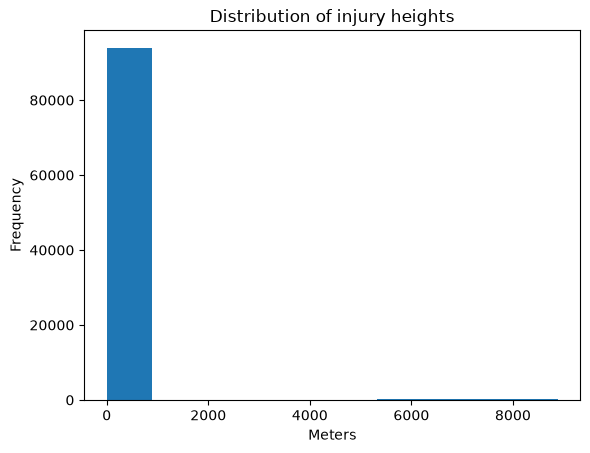

In [207]:
df.injuryhgtm.plot(kind="hist")
plt.title("Distribution of injury heights")
plt.xlabel("Meters")
plt.show()

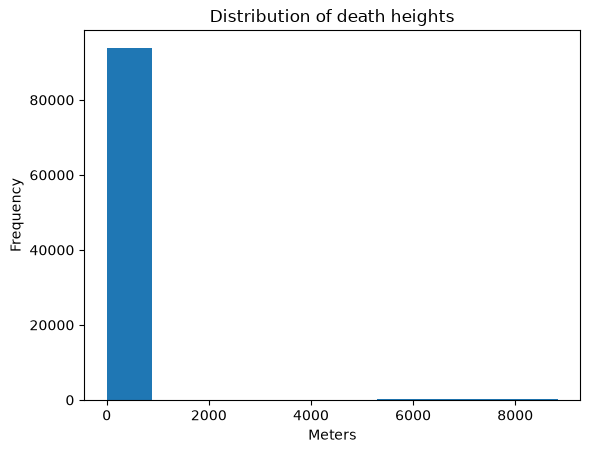

In [208]:
df.deathhgtm.plot(kind="hist")
plt.title("Distribution of death heights")
plt.xlabel("Meters")
plt.show()

In [209]:
df.deathrte.value_counts()

deathrte
0.0    21939
1.0     1018
2.0       27
Name: count, dtype: int64

In [210]:
df.injurytype.value_counts()

injurytype
 0     93201
 3       634
 1       427
 10      269
 4       130
 7       117
 8        92
 11       76
 5        27
 2         9
 6         8
 9         8
-1         1
Name: count, dtype: int64

In [211]:
df.loc[df.injurytype < 0].injuryhgtm

20594    0
Name: injuryhgtm, dtype: int64

In [212]:
df.deathtype.value_counts()

deathtype
0     93812
7       383
4       346
1       123
10       69
9        54
2        52
3        42
8        31
11       30
5        26
6        20
12       11
Name: count, dtype: int64

In [213]:
df.deathclass.value_counts(ascending=False)

deathclass
0    93812
3      491
5      351
4      129
2       94
1       73
6       45
7        4
Name: count, dtype: int64

#### Routes

In [214]:
df[["mroute1", "mroute2", "mroute3", "deathrte"]].describe()

,mroute1,mroute2,mroute3,deathrte
count,94999.000000,94999.000000,94999.000000,22984.000000
mean,0.693144,0.005821,0.000242,0.046641
std,0.489170,0.087527,0.016221,0.216373
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,0.000000,0.000000
max,4.000000,4.000000,2.000000,2.000000


In [215]:
df[["mroute1", "mroute2", "mroute3", "deathrte"]].isna().sum()

mroute1         0
mroute2         0
mroute3         0
deathrte    72015
dtype: int64

#### Summit bid

In [216]:
assert set(df.msmtbid.unique()) == set(range(6))
assert set(df.msmtterm.unique()) == set(range(21))

In [217]:
df[["msmtbid", "msmtterm", "msmtnote1"]]

,msmtbid,msmtterm,msmtnote1
0,1,4,NaN
1,1,4,NaN
2,1,4,NaN
3,1,4,NaN
4,1,4,NaN
...,...,...,...
94994,4,10,0.0
94995,4,10,0.0
94996,4,10,0.0
94997,4,12,0.0


In [218]:
for col in df.select_dtypes(include=["number"]).columns:
  print(col)

mseason
calcage
mperhighpt
mroute1
mroute2
mroute3
mascent1
mascent2
mascent3
deathtype
deathhgtm
deathclass
injurytype
injuryhgtm
msmtbid
msmtterm
hcn
mchksum
msmtnote1
msmtnote2
msmtnote3
deathrte
summit_1_hr
summit_1_min
summit_2_hr
summit_2_min
summit_3_hr
summit_3_min
injury_hr
injury_min
death_hr
death_min


### Boolean variables

In [219]:
df.select_dtypes(include=[bool]).head()

,leader,deputy,bconly,nottobc,support,disabled,hired,sherpa,tibetan,msuccess,...,mo2used,mo2none,mo2climb,mo2descent,mo2sleep,mo2medical,death,ams,weather,injury
0,True,False,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
1,False,True,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False


In [220]:
df.select_dtypes(include=[bool]).isna().sum()

leader        0
deputy        0
bconly        0
nottobc       0
support       0
disabled      0
hired         0
sherpa        0
tibetan       0
msuccess      0
mclaimed      0
mdisputed     0
msolo         0
mtraverse     0
mski          0
mparapente    0
mhighpt       0
mo2used       0
mo2none       0
mo2climb      0
mo2descent    0
mo2sleep      0
mo2medical    0
death         0
ams           0
weather       0
injury        0
dtype: int64

In [221]:
df.select_dtypes(include=[bool]).mean()

leader        0.125496
deputy        0.018348
bconly        0.052958
nottobc       0.012569
support       0.002358
disabled      0.001284
hired         0.232371
sherpa        0.200718
tibetan       0.022337
msuccess      0.432120
mclaimed      0.000979
mdisputed     0.001400
msolo         0.001368
mtraverse     0.003979
mski          0.004147
mparapente    0.000358
mhighpt       0.565764
mo2used       0.276024
mo2none       0.676565
mo2climb      0.264982
mo2descent    0.002063
mo2sleep      0.118970
mo2medical    0.003590
death         0.012495
ams           0.001726
weather       0.000632
injury        0.018927
dtype: float64

In [222]:
df.loc[df.mo2used == df.mo2none].shape

(4504, 92)

In [223]:
df.loc[(df.mo2used == df.mo2none) & df.mo2used].shape

(0, 92)